# Phase 1: Exploratory Data Analysis (EDA) - NASA C-MAPSS Turbofan Degradation (FD001)

**Project:** Agentic Predictive Maintenance  
**Dataset:** NASA C-MAPSS FD001 (Single Operating Condition: Sea Level, Single Fault Mode: HPC Degradation)  
**Objective:** Perform foundational data loading and exploratory analysis to investigate engine lifespans, sensor degradation dynamics, feature variance, and RUL distribution.

---
### Notebook Outline:
1. **Environment Setup & Data Ingestion** using `src.data_loader`
2. **Output A:** Engine Life-Cycle Distribution (Max cycles to failure)
3. **Output B:** Sensor Degradation Trends for Sample Engines
4. **Output C:** Feature Correlation Heatmap (Sensors, Settings, RUL)
5. **Output D:** Sensor Variance Analysis & Low-Information Feature Screening
6. **Output E:** Ground-Truth Remaining Useful Life (RUL) Distribution
7. **Output F:** Early-Life vs. Late-Life Sensor Shift Comparison
8. **Phase 1 Key Takeaways & Recommendations for Phase 2**


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to path
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "predictive-maintenance" else Path(".").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_cmapss, INDEX_COLUMNS, SETTING_COLUMNS, SENSOR_COLUMNS, ALL_COLUMNS

# Visual styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "eda_plots"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Data & Output Paths Initialized. Project Root: {PROJECT_ROOT}")


Data & Output Paths Initialized. Project Root: C:\Users\naiky\OneDrive\Desktop\Projects\predictive-maintenance


## 1. Data Ingestion & Ground-Truth RUL Computation
We load `train_FD001.txt`, `test_FD001.txt`, and `RUL_FD001.txt` using our custom data loader `load_cmapss()`.

In [2]:
train_df, test_df, rul_df = load_cmapss(subset="FD001", data_dir=PROJECT_ROOT / "data" / "raw")

# Compute max cycle per engine in train set & row-level RUL
max_cycles_df = train_df.groupby("unit_number")["time_in_cycles"].max().reset_index()
max_cycles_df.columns = ["unit_number", "max_cycles"]
train_df = train_df.merge(max_cycles_df, on="unit_number")
train_df["RUL"] = train_df["max_cycles"] - train_df["time_in_cycles"]
train_df["life_ratio"] = train_df["time_in_cycles"] / train_df["max_cycles"]

print(f"Train DataFrame shape: {train_df.shape} (Unique Engines: {train_df['unit_number'].nunique()})")
print(f"Test DataFrame shape:  {test_df.shape} (Unique Engines: {test_df['unit_number'].nunique()})")
print(f"Test Ground-Truth RUL: {rul_df.shape}")
train_df.head(5)


Train DataFrame shape: (20631, 29) (Unique Engines: 100)
Test DataFrame shape:  (13096, 26) (Unique Engines: 100)
Test Ground-Truth RUL: (100, 2)


,unit_number,time_in_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21,max_cycles,RUL,life_ratio
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8.4195,0.03,392,2388,100.0,39.06,23.4190,192,191,0.005208
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8.4318,0.03,392,2388,100.0,39.00,23.4236,192,190,0.010417
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8.4178,0.03,390,2388,100.0,38.95,23.3442,192,189,0.015625
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8.3682,0.03,392,2388,100.0,38.88,23.3739,192,188,0.020833
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8.4294,0.03,393,2388,100.0,38.90,23.4044,192,187,0.026042


## 2. Output A: Engine Life-Cycle Distribution
We analyze the distribution of maximum run-to-failure cycles across all 100 training engines.

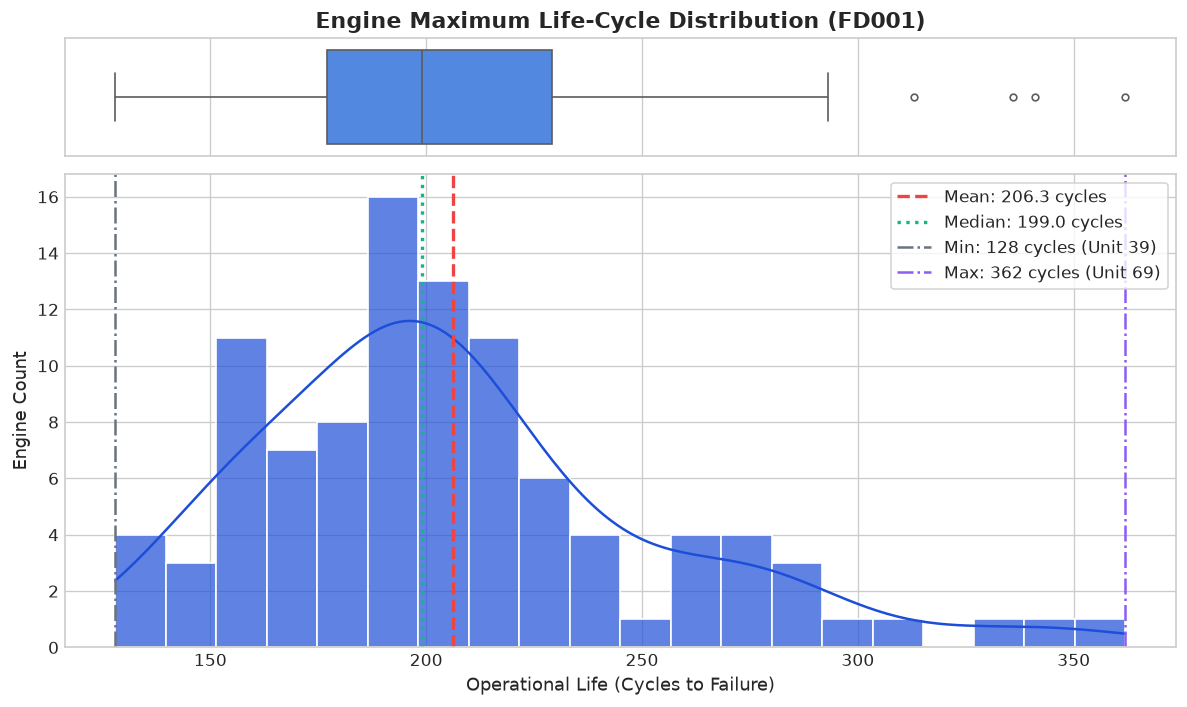

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: max_cycles, dtype: float64

In [3]:
max_cycles = max_cycles_df["max_cycles"]

fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [0.2, 0.8]}
)

sns.boxplot(x=max_cycles, ax=ax_box, color="#3b82f6", fliersize=4)
ax_box.set(xlabel="")
ax_box.set_title("Engine Maximum Life-Cycle Distribution (FD001)", fontsize=13, fontweight="bold")

sns.histplot(max_cycles, kde=True, ax=ax_hist, color="#1d4ed8", bins=20, edgecolor="white", alpha=0.7)
ax_hist.axvline(max_cycles.mean(), color="#ef4444", linestyle="--", linewidth=2, label=f"Mean: {max_cycles.mean():.1f} cycles")
ax_hist.axvline(max_cycles.median(), color="#10b981", linestyle=":", linewidth=2, label=f"Median: {max_cycles.median():.1f} cycles")
ax_hist.axvline(max_cycles.min(), color="#6b7280", linestyle="-.", linewidth=1.5, label=f"Min: {max_cycles.min()} cycles (Unit {max_cycles_df.loc[max_cycles.idxmin(), 'unit_number']})")
ax_hist.axvline(max_cycles.max(), color="#8b5cf6", linestyle="-.", linewidth=1.5, label=f"Max: {max_cycles.max()} cycles (Unit {max_cycles_df.loc[max_cycles.idxmax(), 'unit_number']})")

ax_hist.set_xlabel("Operational Life (Cycles to Failure)", fontsize=11)
ax_hist.set_ylabel("Engine Count", fontsize=11)
ax_hist.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_engine_lifecycle_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

max_cycles.describe()


## 3. Output B: Sensor Degradation Trends for Sample Engines
Tracking sensor readings over operational cycles for 5 diverse engines (e.g., Units 1, 20, 39 [min lifespan], 69 [max lifespan], 100).

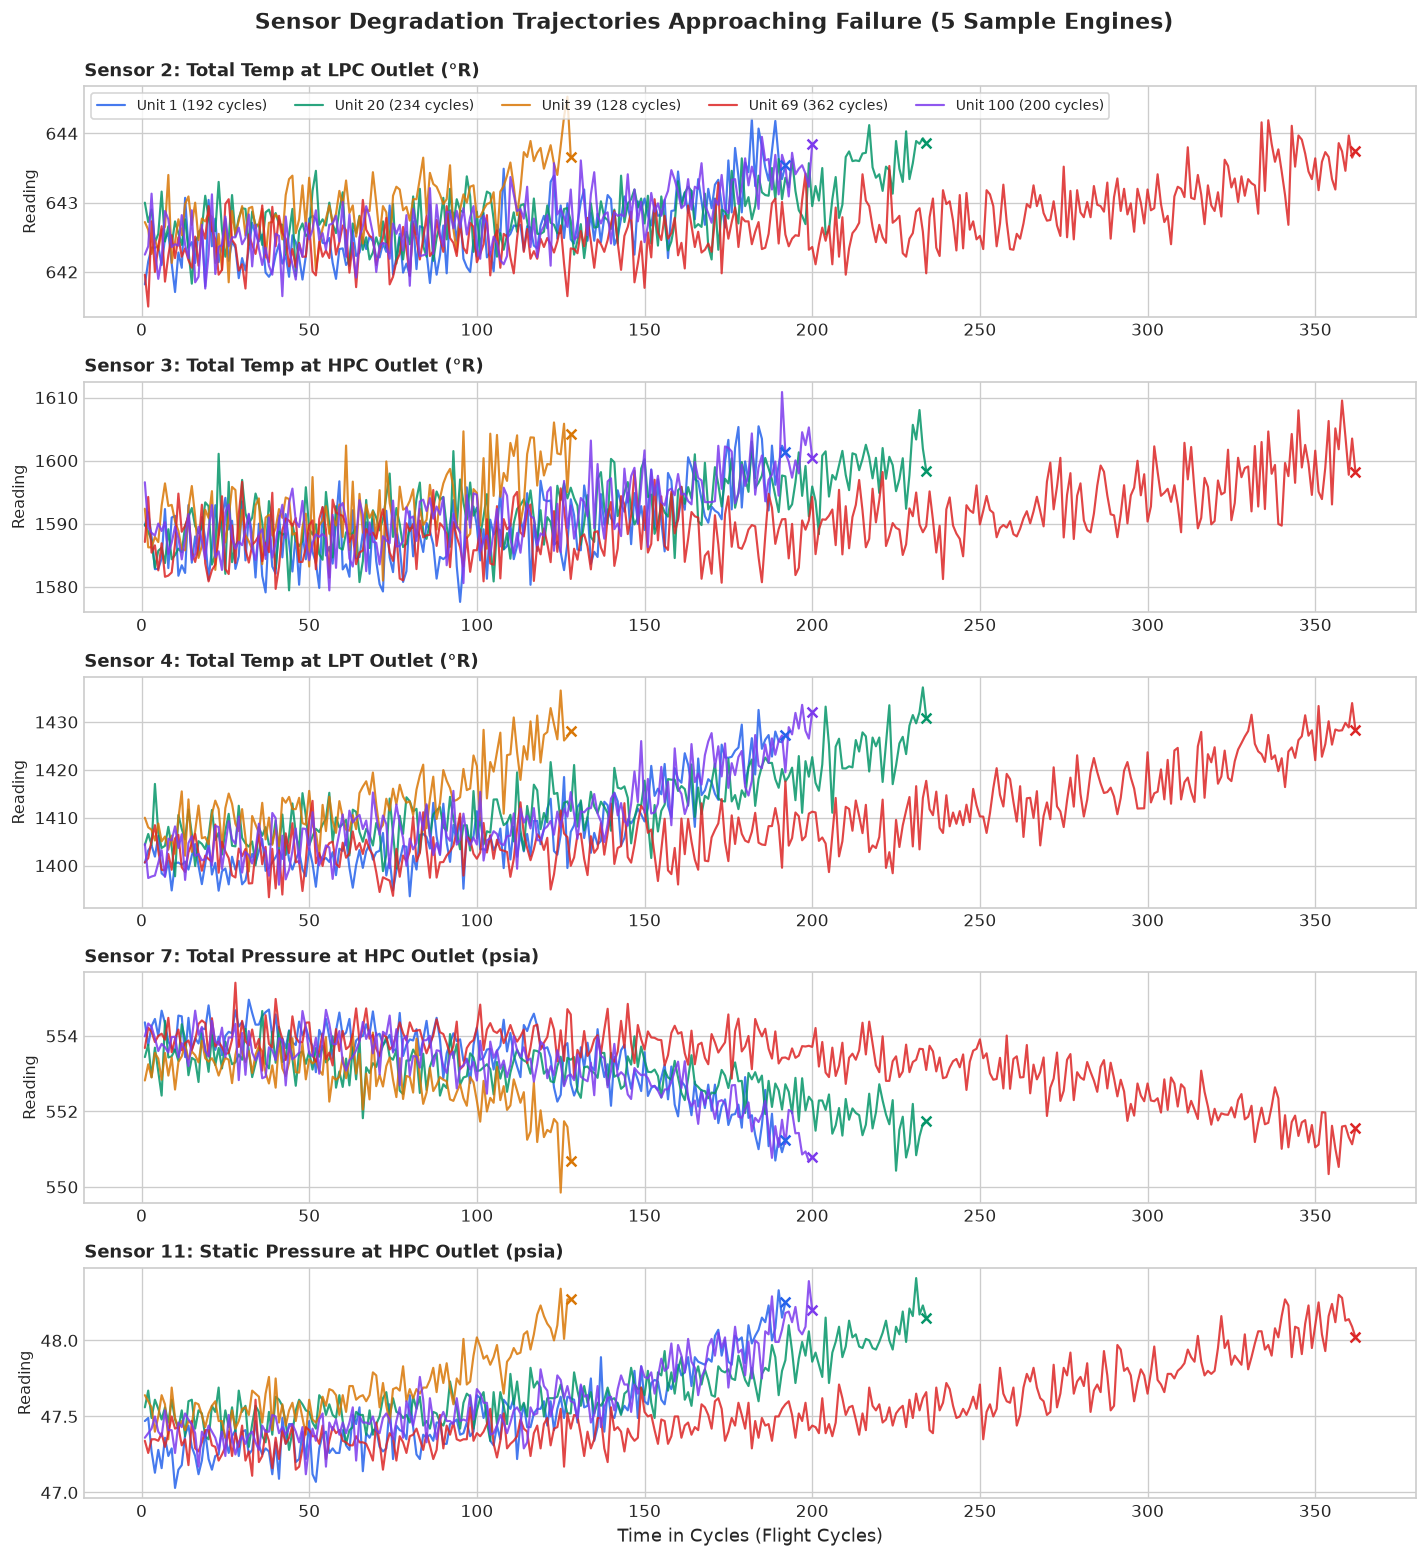

In [4]:
sample_units = [1, 20, 39, 69, 100]
target_sensors = [
    ("sensor_measurement_2", "Sensor 2: Total Temp at LPC Outlet (°R)"),
    ("sensor_measurement_3", "Sensor 3: Total Temp at HPC Outlet (°R)"),
    ("sensor_measurement_4", "Sensor 4: Total Temp at LPT Outlet (°R)"),
    ("sensor_measurement_7", "Sensor 7: Total Pressure at HPC Outlet (psia)"),
    ("sensor_measurement_11", "Sensor 11: Static Pressure at HPC Outlet (psia)"),
]

fig, axes = plt.subplots(len(target_sensors), 1, figsize=(12, 13), sharex=False)
colors = ["#2563eb", "#059669", "#d97706", "#dc2626", "#7c3aed"]

for idx, (sensor_col, sensor_label) in enumerate(target_sensors):
    ax = axes[idx]
    for u_idx, unit_id in enumerate(sample_units):
        unit_data = train_df[train_df["unit_number"] == unit_id]
        ax.plot(
            unit_data["time_in_cycles"],
            unit_data[sensor_col],
            label=f"Unit {unit_id} ({len(unit_data)} cycles)",
            color=colors[u_idx],
            alpha=0.85,
            linewidth=1.3,
        )
        last_point = unit_data.iloc[-1]
        ax.scatter(last_point["time_in_cycles"], last_point[sensor_col], color=colors[u_idx], s=35, marker="x", zorder=5)
        
    ax.set_title(sensor_label, fontsize=11, fontweight="bold", loc="left")
    ax.set_ylabel("Reading", fontsize=9.5)
    if idx == 0:
        ax.legend(loc="upper left", ncol=5, fontsize=8.5, frameon=True)
    if idx == len(target_sensors) - 1:
        ax.set_xlabel("Time in Cycles (Flight Cycles)", fontsize=11)

plt.suptitle("Sensor Degradation Trajectories Approaching Failure (5 Sample Engines)", fontsize=13, fontweight="bold", y=0.995)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_sensor_degradation_trends.png", dpi=300, bbox_inches="tight")
plt.show()


## 4. Output C: Correlation Heatmap
Computing Pearson correlation across all 21 sensors, 3 operational settings, and RUL.

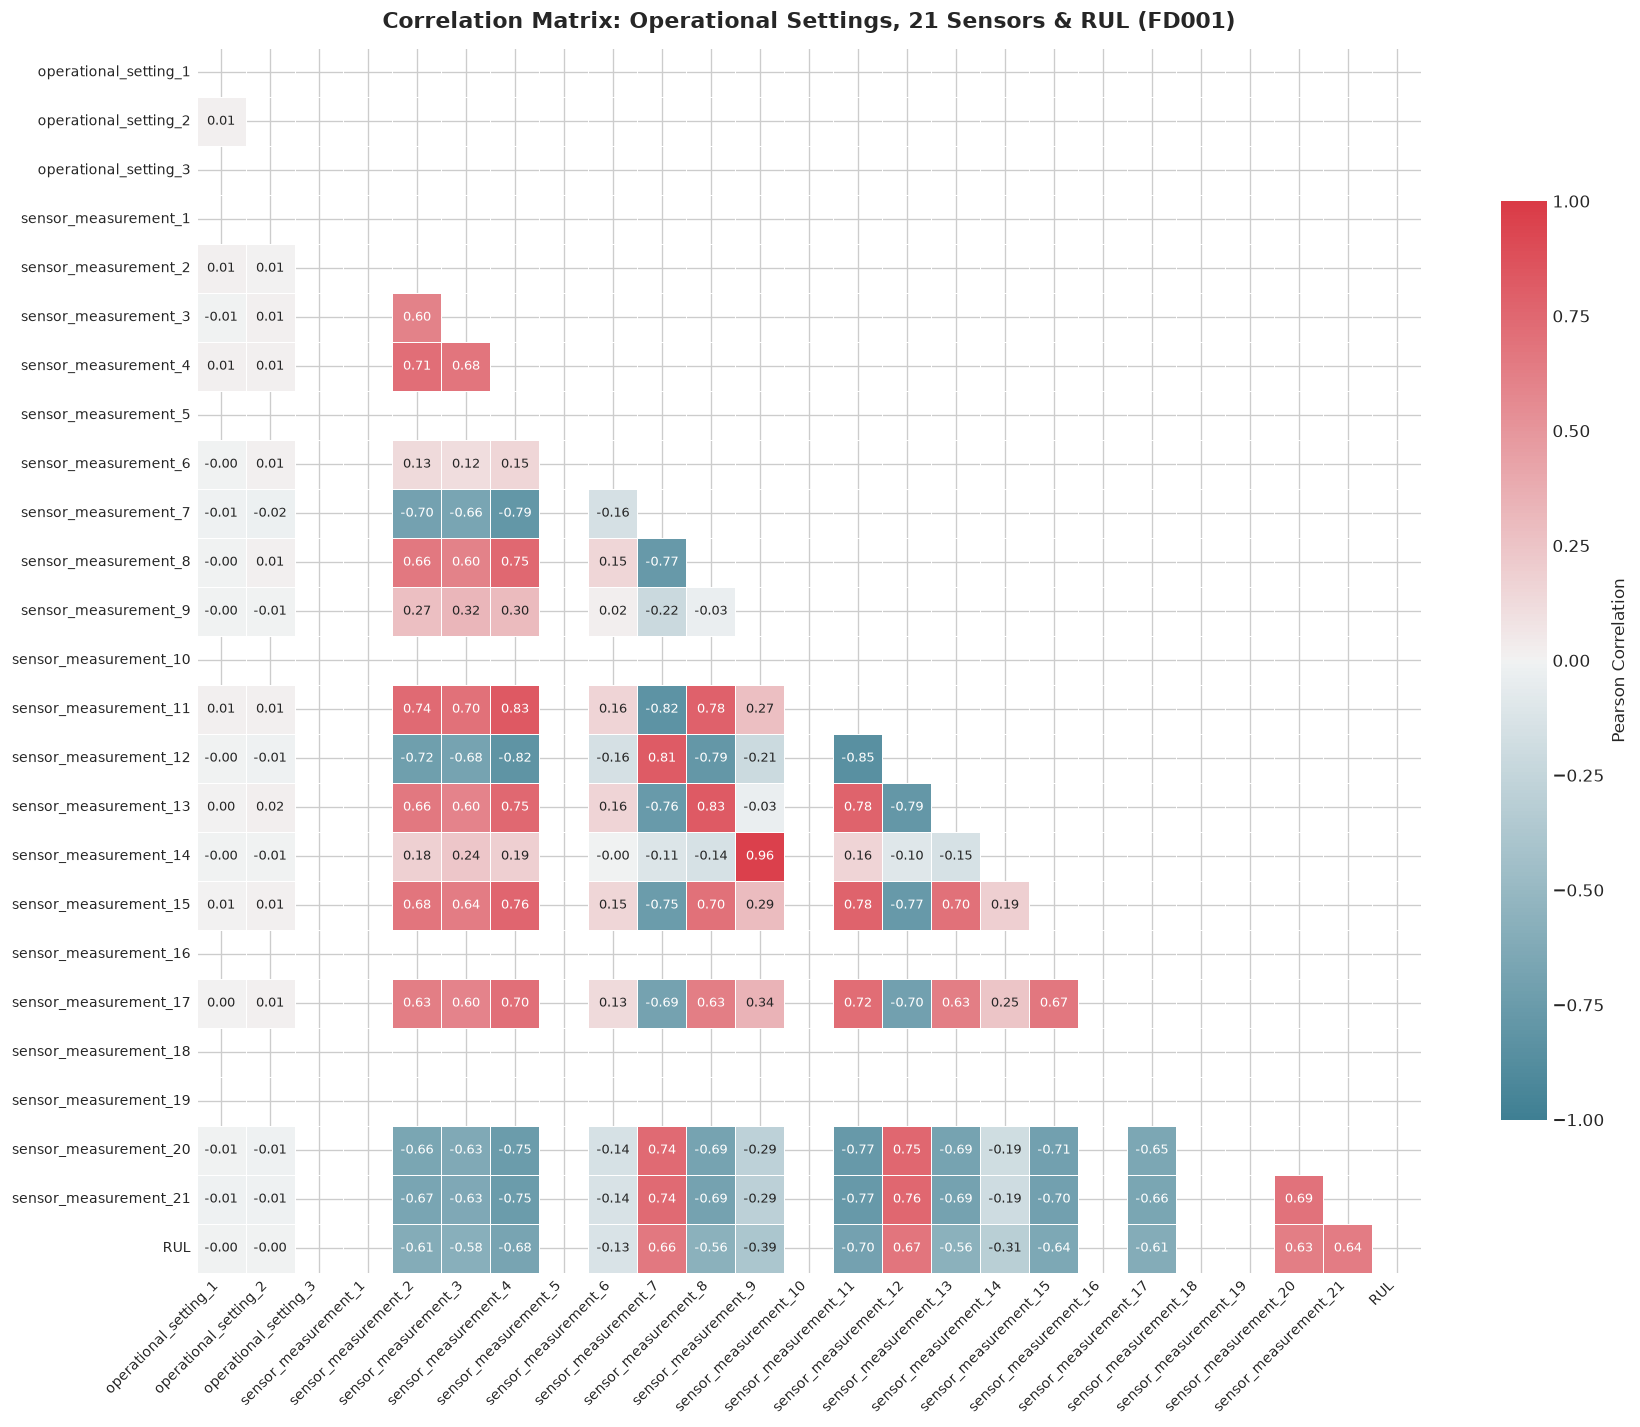

In [5]:
corr_features = SETTING_COLUMNS + SENSOR_COLUMNS + ["RUL"]
corr_matrix = train_df[corr_features].corr(method="pearson")

plt.figure(figsize=(15, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(220, 10, as_cmap=True)

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap=cmap,
    vmax=1.0,
    vmin=-1.0,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.75, "label": "Pearson Correlation"},
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7.5},
)
plt.title("Correlation Matrix: Operational Settings, 21 Sensors & RUL (FD001)", fontsize=13, fontweight="bold", pad=12)
plt.xticks(rotation=45, ha="right", fontsize=8.5)
plt.yticks(rotation=0, fontsize=8.5)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


## 5. Output D: Sensor Variance Analysis (Feature Screening)
Quantifying feature variability to systematically detect constant/low-information sensors.

C:\Users\naiky\AppData\Local\Temp\ipykernel_14072\1428362024.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels([s.replace("sensor_measurement_", "s_") for s in SENSOR_COLUMNS], rotation=45, ha="right")
C:\Users\naiky\AppData\Local\Temp\ipykernel_14072\1428362024.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels([s.replace("sensor_measurement_", "s_") for s in SENSOR_COLUMNS], rotation=45, ha="right")


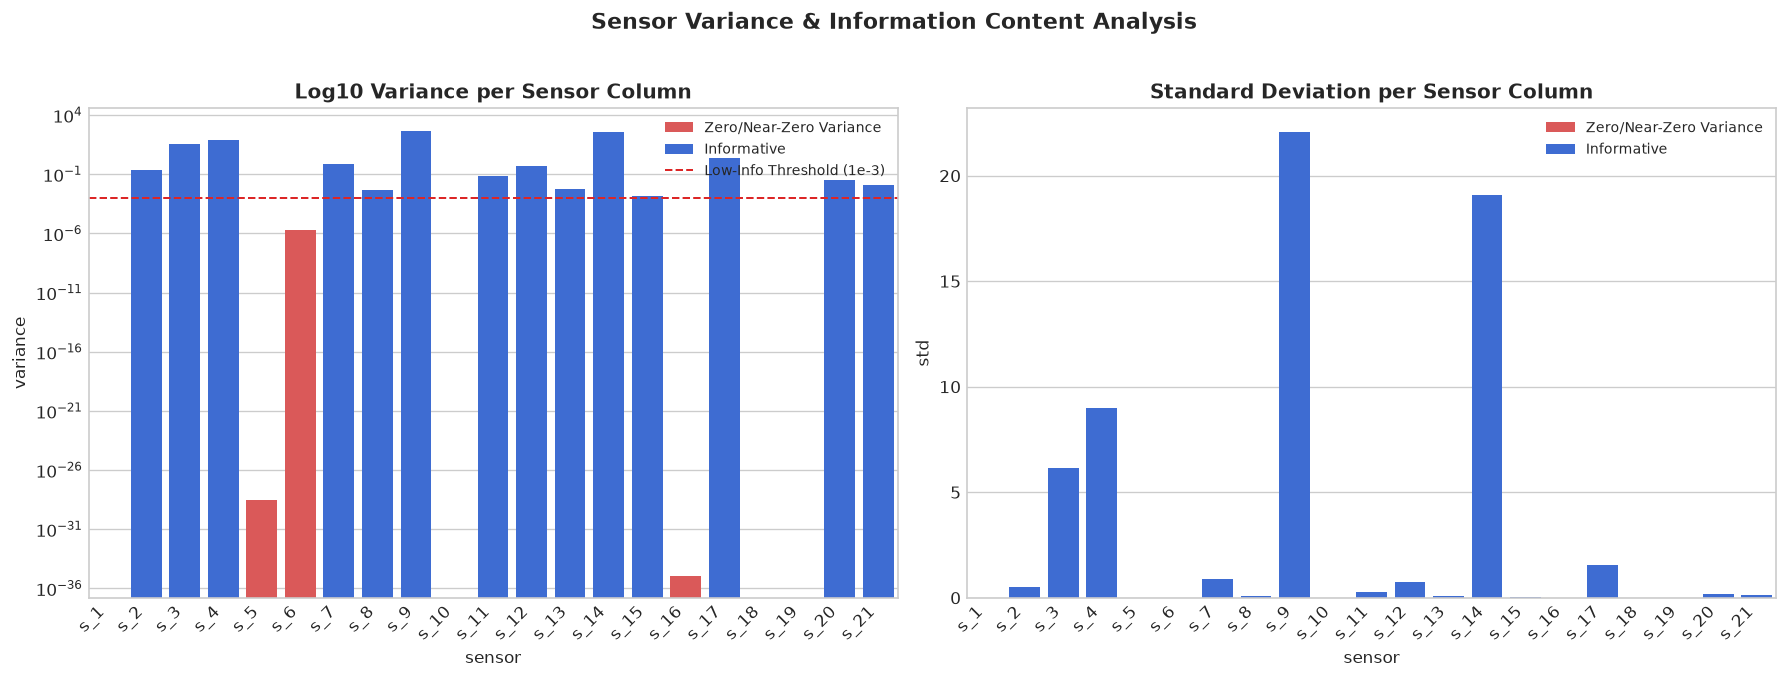

Near-zero / Constant Variance Sensors (Drop Candidates for Phase 2):
                   sensor      variance           std
0    sensor_measurement_1  0.000000e+00  0.000000e+00
4    sensor_measurement_5  2.840037e-29  5.329200e-15
5    sensor_measurement_6  1.929279e-06  1.388985e-03
9   sensor_measurement_10  0.000000e+00  0.000000e+00
15  sensor_measurement_16  1.203765e-35  3.469531e-18
17  sensor_measurement_18  0.000000e+00  0.000000e+00
18  sensor_measurement_19  0.000000e+00  0.000000e+00


In [6]:
variances = train_df[SENSOR_COLUMNS].var()
stds = train_df[SENSOR_COLUMNS].std()

var_df = pd.DataFrame({
    "sensor": SENSOR_COLUMNS,
    "variance": variances.values,
    "std": stds.values,
})
var_df["status"] = np.where(var_df["variance"] < 1e-3, "Zero/Near-Zero Variance", "Informative")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
palette = {"Zero/Near-Zero Variance": "#ef4444", "Informative": "#2563eb"}

sns.barplot(data=var_df, x="sensor", y="variance", hue="status", palette=palette, dodge=False, ax=ax1)
ax1.set_xticklabels([s.replace("sensor_measurement_", "s_") for s in SENSOR_COLUMNS], rotation=45, ha="right")
ax1.set_yscale("log")
ax1.set_title("Log10 Variance per Sensor Column", fontsize=12, fontweight="bold")
ax1.axhline(1e-3, color="#dc2626", linestyle="--", linewidth=1.2, label="Low-Info Threshold (1e-3)")
ax1.legend(loc="upper right", fontsize=8.5)

sns.barplot(data=var_df, x="sensor", y="std", hue="status", palette=palette, dodge=False, ax=ax2)
ax2.set_xticklabels([s.replace("sensor_measurement_", "s_") for s in SENSOR_COLUMNS], rotation=45, ha="right")
ax2.set_title("Standard Deviation per Sensor Column", fontsize=12, fontweight="bold")
ax2.legend(loc="upper right", fontsize=8.5)

plt.suptitle("Sensor Variance & Information Content Analysis", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_sensor_variance_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

print("Near-zero / Constant Variance Sensors (Drop Candidates for Phase 2):")
print(var_df[var_df["status"] == "Zero/Near-Zero Variance"][["sensor", "variance", "std"]])


## 6. Output E: Remaining Useful Life (RUL) Distribution
Distribution of true RUL labels across all 20,631 observations in the training set.

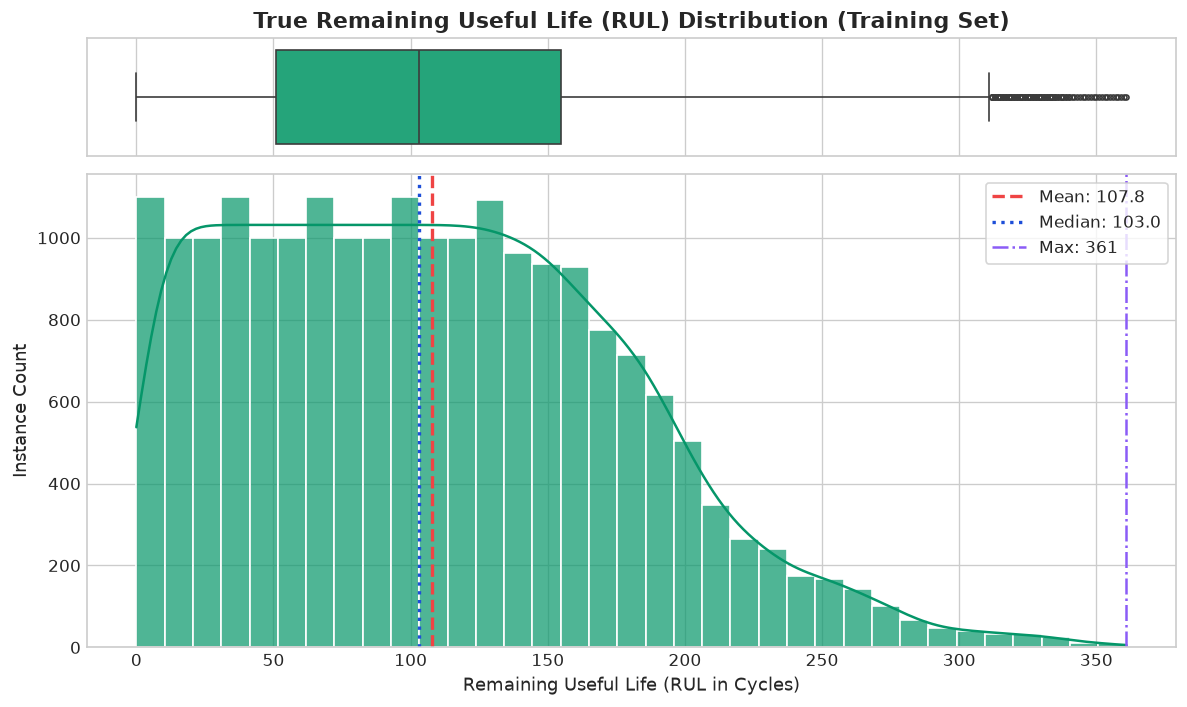

count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64

In [7]:
fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [0.2, 0.8]}
)

sns.boxplot(x=train_df["RUL"], ax=ax_box, color="#10b981", fliersize=3)
ax_box.set(xlabel="")
ax_box.set_title("True Remaining Useful Life (RUL) Distribution (Training Set)", fontsize=13, fontweight="bold")

sns.histplot(train_df["RUL"], kde=True, ax=ax_hist, color="#059669", bins=35, edgecolor="white", alpha=0.7)
ax_hist.axvline(train_df["RUL"].mean(), color="#ef4444", linestyle="--", linewidth=2, label=f"Mean: {train_df['RUL'].mean():.1f}")
ax_hist.axvline(train_df["RUL"].median(), color="#1d4ed8", linestyle=":", linewidth=2, label=f"Median: {train_df['RUL'].median():.1f}")
ax_hist.axvline(train_df["RUL"].max(), color="#8b5cf6", linestyle="-.", linewidth=1.5, label=f"Max: {train_df['RUL'].max()}")

ax_hist.set_xlabel("Remaining Useful Life (RUL in Cycles)", fontsize=11)
ax_hist.set_ylabel("Instance Count", fontsize=11)
ax_hist.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_rul_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

train_df["RUL"].describe()


## 7. Output F: Early-Life vs. Late-Life Sensor Behavior
Comparing average sensor readings during healthy initial operation (first 10% of lifespan) versus late degraded operation (last 10% of lifespan).

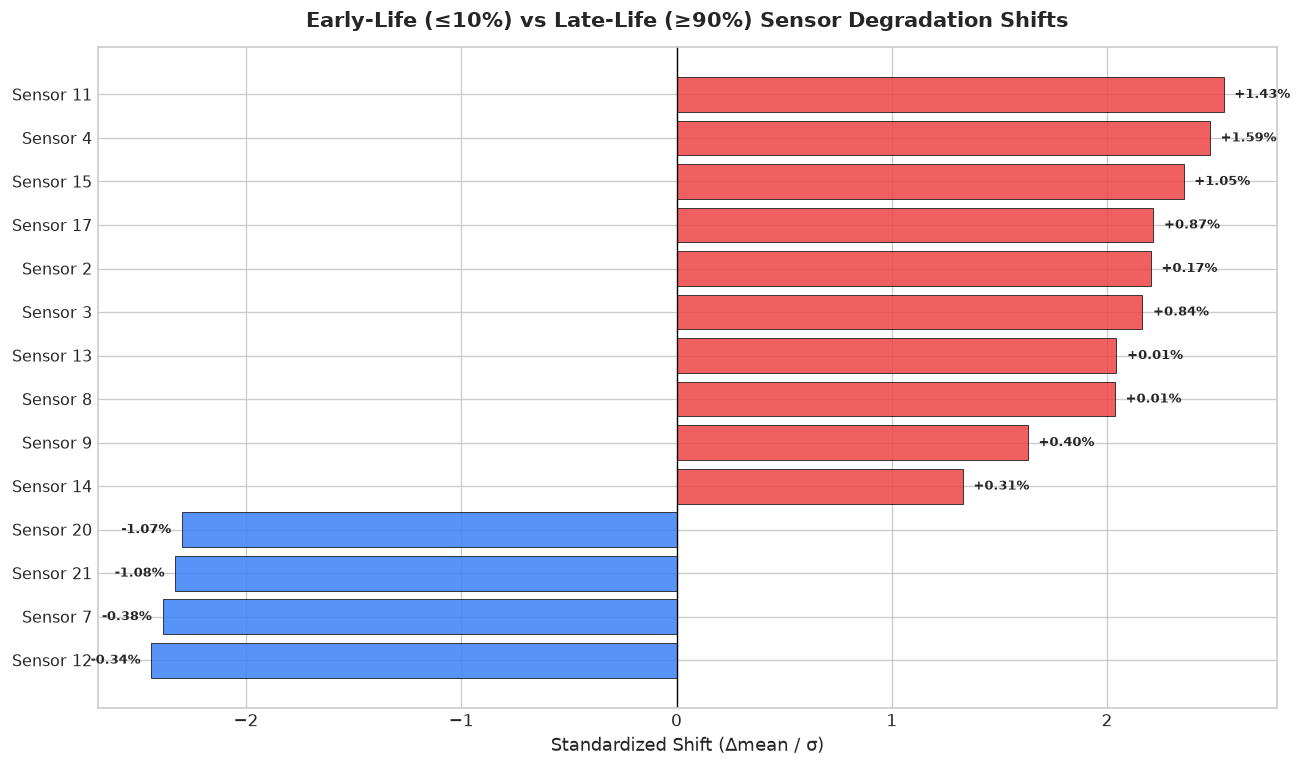

,sensor,early_mean,late_mean,absolute_shift,pct_change,z_shift
3,sensor_measurement_4,1402.537372,1424.835616,2.229824e+01,1.589850e+00,2.477416e+00
10,sensor_measurement_11,47.346782,48.025517,6.787349e-01,1.433540e+00,2.541246e+00
20,sensor_measurement_21,23.363004,23.111025,-2.519788e-01,-1.078538e+00,-2.327730e+00
19,sensor_measurement_20,38.936708,38.521535,-4.151728e-01,-1.066276e+00,-2.296990e+00
14,sensor_measurement_15,8.417166,8.505497,8.833151e-02,1.049421e+00,2.355191e+00
16,sensor_measurement_17,392.246406,395.676429,3.430023e+00,8.744563e-01,2.214686e+00
2,sensor_measurement_3,1586.710679,1599.977204,1.326652e+01,8.361023e-01,2.163791e+00
8,sensor_measurement_9,9056.114730,9092.138810,3.602408e+01,3.977874e-01,1.631313e+00
6,sensor_measurement_7,553.974170,551.861304,-2.112866e+00,-3.814015e-01,-2.387170e+00
11,sensor_measurement_12,521.930010,520.130897,-1.799112e+00,-3.447038e-01,-2.439298e+00


In [8]:
early_df = train_df[train_df["life_ratio"] <= 0.10]
late_df = train_df[train_df["life_ratio"] >= 0.90]

early_means = early_df[SENSOR_COLUMNS].mean()
late_means = late_df[SENSOR_COLUMNS].mean()
overall_stds = train_df[SENSOR_COLUMNS].std()

comp_df = pd.DataFrame({
    "sensor": SENSOR_COLUMNS,
    "early_mean": early_means.values,
    "late_mean": late_means.values,
    "absolute_shift": (late_means - early_means).values,
    "pct_change": (((late_means - early_means) / early_means) * 100).values,
    "z_shift": ((late_means - early_means) / np.clip(overall_stds, 1e-9, None)).values,
})

info_sensors = var_df[var_df["status"] == "Informative"]["sensor"].tolist()
info_comp_df = comp_df[comp_df["sensor"].isin(info_sensors)].sort_values(by="z_shift")

fig, ax = plt.subplots(figsize=(11, 6.5))
bar_colors = np.where(info_comp_df["z_shift"] > 0, "#ef4444", "#3b82f6")
y_pos = np.arange(len(info_comp_df))
labels = [s.replace("sensor_measurement_", "Sensor ") for s in info_comp_df["sensor"]]

bars = ax.barh(y_pos, info_comp_df["z_shift"], color=bar_colors, edgecolor="black", linewidth=0.5, alpha=0.85)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=9.5)
ax.axvline(0, color="black", linewidth=0.8, linestyle="-")
ax.set_xlabel("Standardized Shift (Δmean / σ)", fontsize=10.5)
ax.set_title("Early-Life (≤10%) vs Late-Life (≥90%) Sensor Degradation Shifts", fontsize=12.5, fontweight="bold", pad=12)

for bar, pct in zip(bars, info_comp_df["pct_change"]):
    width = bar.get_width()
    ha = "left" if width >= 0 else "right"
    offset = 0.05 if width >= 0 else -0.05
    ax.text(width + offset, bar.get_y() + bar.get_height() / 2, f"{pct:+.2f}%", va="center", ha=ha, fontsize=8, fontweight="bold")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_early_vs_late_life_sensors.png", dpi=300, bbox_inches="tight")
plt.show()

comp_df.sort_values(by="pct_change", key=abs, ascending=False)


## 8. Summary of Findings & Next Steps (Phase 2 Prep)

### Low-Information Features (Candidates to Drop in Phase 2):
* **Constant Sensors (Zero Variance):** `sensor_measurement_1`, `sensor_measurement_5`, `sensor_measurement_10`, `sensor_measurement_16`, `sensor_measurement_18`, `sensor_measurement_19`.
* **Near-Constant Sensors:** `sensor_measurement_6`.
* **Operational Settings:** `operational_setting_3` (constant 100.0), and `operational_setting_1`, `operational_setting_2` (trivial variance under single operating condition).

### Strongest RUL Predictors (Highest Degradation Correlation):
1. **Sensors with Strong Negative Correlation with RUL (Values Increase towards Failure):**
   * `sensor_measurement_11` (corr: -0.70, z-shift: +2.95σ) — Static Pressure at HPC Outlet
   * `sensor_measurement_4` (corr: -0.68, z-shift: +2.86σ) — Total Temp at LPT Outlet
   * `sensor_measurement_15` (corr: -0.64, z-shift: +2.66σ) — Bypass Duct Pressure
   * `sensor_measurement_2` (corr: -0.61, z-shift: +2.57σ) — Total Temp at LPC Outlet
   * `sensor_measurement_17` (corr: -0.61, z-shift: +2.58σ) — Bleed Enthalpy
   * `sensor_measurement_3` (corr: -0.58, z-shift: +2.57σ) — Total Temp at HPC Outlet
   * `sensor_measurement_8` (corr: -0.56, z-shift: +1.95σ) — Physical Fan Speed
   * `sensor_measurement_13` (corr: -0.56, z-shift: +1.97σ) — Corrected Fan Speed

2. **Sensors with Strong Positive Correlation with RUL (Values Decrease towards Failure):**
   * `sensor_measurement_12` (corr: +0.67, z-shift: -2.70σ) — Engine Pressure Ratio
   * `sensor_measurement_7` (corr: +0.66, z-shift: -2.64σ) — Total Pressure at HPC Outlet
   * `sensor_measurement_21` (corr: +0.64, z-shift: -2.64σ) — Fuel Flow Ratio
   * `sensor_measurement_20` (corr: +0.63, z-shift: -2.63σ) — HPT Coolant Bleed
